# Análisis Operativo y Comercial: MaderNova S.A.

## Objetivo
Evaluar comportamiento productivo y de desempeño de la red de distribución de tableros de madera, correlacionando consumo de energía, tiempos de despacho, tipo de material y volúmenes de merma.

## Datos
Se utiliza el archivo `dataset_set_B_madernova.xlsx`, el que documenta variables de las tres plantas operativas y tres canales comerciales a lo largo de diversos periodos.

## Metodología
- **Carga y segregación:** División del dataset primario para separar contexto de Producción del área Comercial utilizando `pandas`.
- **Análisis Estadístico:** Cálculo de indicadores críticos de eficiencia y dispersión guardados mediante `joblib`.
- **Visualización:** Generación de un dashboard gerencial multifacético utilizando `matplotlib` y `seaborn`.

## Resultados
Se detecta una alta variabilidad en los tiempos de despacho asociados a los canales, variando fuertemente según la planta. El volumen no muestra relación perfectamente escalonada con la merma, lo cual indica que las pérdidas de material pueden obedecer a incidentes en la línea de producción y no meramente a la cantidad de tableros fabricados.


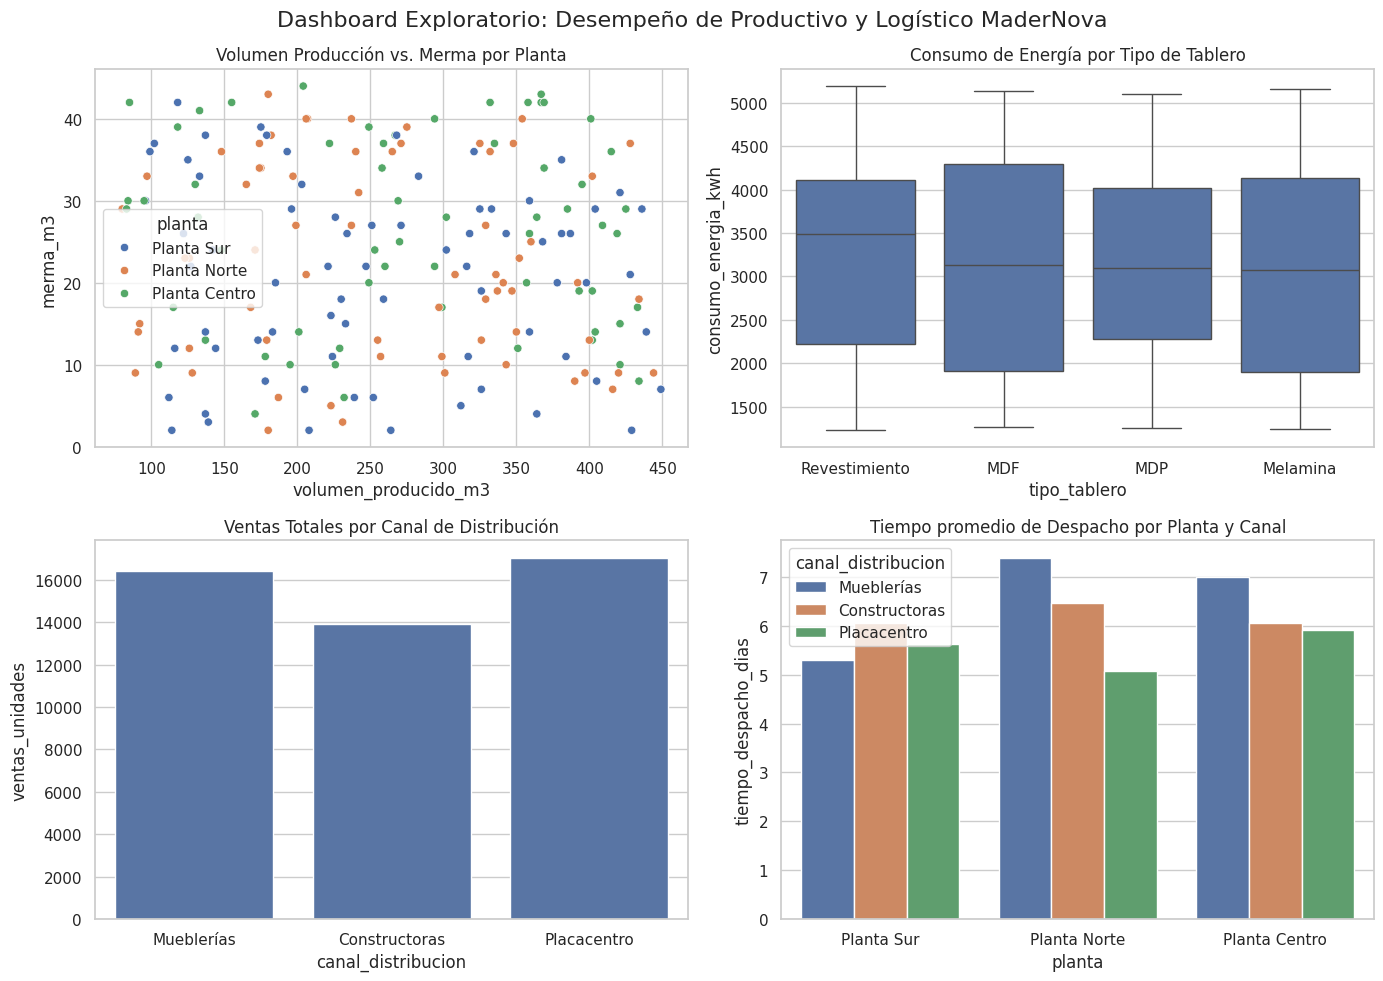

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Carga de datos
df = pd.read_excel('dataset_set_B_madernova.xlsx')

# 2. Generación archivos de salida para áreas específicas
# Área Producción
df_produccion = df[['fecha_registro', 'planta', 'tipo_tablero', 'volumen_producido_m3',
                    'merma_m3', 'consumo_energia_kwh', 'tiempo_produccion_hr']]
df_produccion.to_excel('reporte_produccion.xlsx', index=False)

# Área Comercial y Distribución
df_comercial = df[['fecha_registro', 'tipo_tablero', 'ventas_unidades',
                   'canal_distribucion', 'tiempo_despacho_dias']]
df_comercial.to_excel('reporte_comercial.xlsx', index=False)

# 3. Creación Dashboard Exploratorio
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Dashboard Exploratorio: Desempeño de Productivo y Logístico MaderNova', fontsize=16)

# Relación Volumen vs Merma
sns.scatterplot(data=df, x='volumen_producido_m3', y='merma_m3', hue='planta', ax=axes[0, 0])
axes[0, 0].set_title('Volumen Producción vs. Merma por Planta')

# Análisis Consumo Energético
sns.boxplot(data=df, x='tipo_tablero', y='consumo_energia_kwh', ax=axes[0, 1])
axes[0, 1].set_title('Consumo de Energía por Tipo de Tablero')

# Desempeño Ventas
sns.barplot(data=df, x='canal_distribucion', y='ventas_unidades', estimator=sum, errorbar=None, ax=axes[1, 0])
axes[1, 0].set_title('Ventas Totales por Canal de Distribución')

# Tiempos Logísticos
sns.barplot(data=df, x='planta', y='tiempo_despacho_dias', hue='canal_distribucion', errorbar=None, ax=axes[1, 1])
axes[1, 1].set_title('Tiempo promedio de Despacho por Planta y Canal')

plt.tight_layout()
plt.savefig('dashboard_madernova.png')
plt.show()

In [6]:
%%writefile funciones_madernova.py
import numpy as np
from joblib import dump

def calcular_kpis_logisticos(df, ruta_salida):
    """Calcula indicadores logísticos clave y guarda usando joblib."""
    # Uso de NumPy para cálculos
    despacho_prom = np.mean(df['tiempo_despacho_dias'])
    despacho_std = np.std(df['tiempo_despacho_dias'], ddof=1)
    ventas_totales = np.sum(df['ventas_unidades'])

    metricas = {
        'Despacho_Promedio_Dias': round(despacho_prom, 2),
        'Desviacion_Despacho': round(despacho_std, 2),
        'Ventas_Totales_Unidades': int(ventas_totales)
    }

    # Uso de Joblib para persistencia
    dump(metricas, ruta_salida)

    return metricas

Writing funciones_madernova.py


In [7]:
# 1. Importación de función desde el archivo externo creado
from funciones_madernova import calcular_kpis_logisticos

# 2. Aplicación de función al dataset del análisis
print("Ejecutando módulo externo para cálculo de KPIs...")
archivo_salida = 'kpis_madernova.joblib'
resultados_kpi = calcular_kpis_logisticos(df, archivo_salida)

# 3. Visualización de resultados aplicados
print("\n== Resultados obtenidos mediante código modular ==")
for kpi, valor in resultados_kpi.items():
    print(f"{kpi}: {valor}")
print(f"\nArchivo guardado exitosamente como: {archivo_salida}")

Ejecutando módulo externo para cálculo de KPIs...

== Resultados obtenidos mediante código modular ==
Despacho_Promedio_Dias: 6.14
Desviacion_Despacho: 3.39
Ventas_Totales_Unidades: 47329

Archivo guardado exitosamente como: kpis_madernova.joblib
